# Distance of a Point from a Plane

## Mathematical Foundations for Logistic Regression and SVM

This notebook turns the geometry into visual experiments. It covers a 2D line (the 2D version of a plane), signed distance, the normal vector, a 3D plane, and the role of the bias term.

**Core formula**

For the plane $\mathbf{W}^T\mathbf{X}+b=0$, the signed distance of point $\mathbf{S}$ is:

$$
d_{\text{signed}}=\frac{\mathbf{W}^T\mathbf{S}+b}{\|\mathbf{W}\|}
$$

The ordinary geometric distance is:

$$
d_{\text{actual}}=|d_{\text{signed}}|
$$


## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)


## 2. A 2D decision boundary and points on either side

In two dimensions, a plane becomes a line. We use \(w_1x+w_2y+b=0\). Points on opposite sides have signed distances with opposite signs.

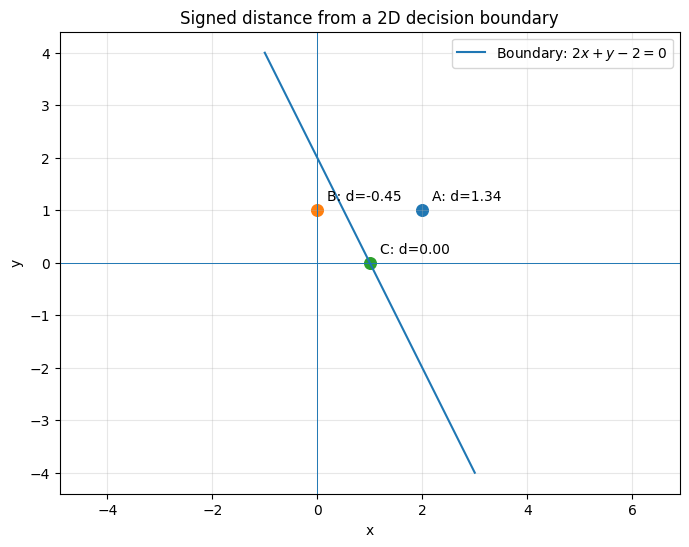

In [2]:
# Decision boundary: 2x + y - 2 = 0
W = np.array([2.0, 1.0])
b = -2.0

# Points selected on different sides of the boundary
points = {
    "A": np.array([2.0, 1.0]),
    "B": np.array([0.0, 1.0]),
    "C": np.array([1.0, 0.0]),  # lies on the boundary
}

x = np.linspace(-1, 3, 300)
y_boundary = -(W[0] * x + b) / W[1]

plt.figure(figsize=(8, 6))
plt.plot(x, y_boundary, label=r"Boundary: $2x+y-2=0$")
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)

for label, point in points.items():
    score = W @ point + b
    signed_distance = score / np.linalg.norm(W)
    plt.scatter(point[0], point[1], s=70)
    plt.annotate(
        f"{label}: d={signed_distance:.2f}",
        (point[0], point[1]),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Signed distance from a 2D decision boundary")
plt.grid(True, alpha=0.3)
plt.legend()
plt.axis("equal")
plt.show()


### What to notice

- A positive signed distance means the point is on the side toward which \(\mathbf{W}\) points.
- A negative signed distance means it is on the opposite side.
- A zero signed distance means the point lies on the boundary.
- The line is the decision boundary; it is not itself a class label.


## 3. Calculate signed and actual distance

Try changing the point or the normal vector. The signed distance may be negative, but actual geometric distance is never negative.

In [3]:
W = np.array([2.0, 1.0])
b = -2.0
S = np.array([0.0, 1.0])

signed_distance = (W @ S + b) / np.linalg.norm(W)
actual_distance = abs(signed_distance)

print("Point S:", S)
print("W dot S + b:", W @ S + b)
print("Norm of W:", np.linalg.norm(W))
print("Signed distance:", signed_distance)
print("Actual geometric distance:", actual_distance)


Point S: [0. 1.]
W dot S + b: -1.0
Norm of W: 2.23606797749979
Signed distance: -0.4472135954999579
Actual geometric distance: 0.4472135954999579


## 4. Visualize the Normal Vector

The normal vector is perpendicular to the decision boundary. Here, $\mathbf{W}=(2,1)$.

The vector is drawn from a point on the line to make the perpendicular direction visible.

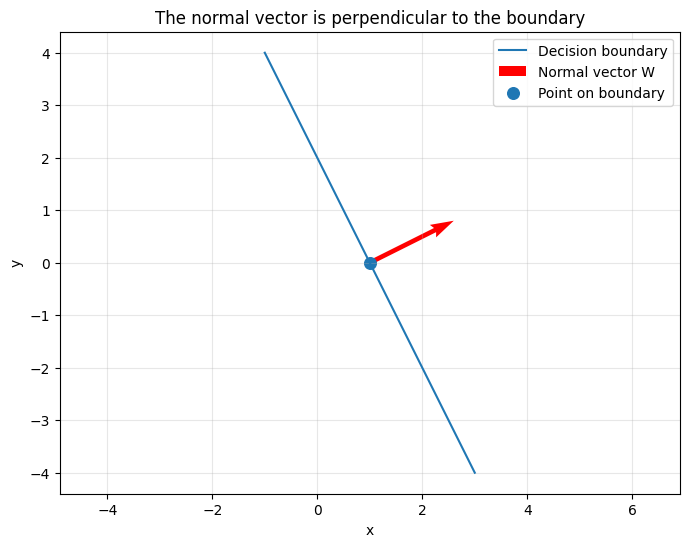

In [4]:
W = np.array([2.0, 1.0])
b = -2.0

# One point on the boundary: (1, 0), because 2(1) + 0 - 2 = 0
P = np.array([1.0, 0.0])
normal_scale = 0.8

x = np.linspace(-1, 3, 300)
y = -(W[0] * x + b) / W[1]

plt.figure(figsize=(8, 6))
plt.plot(x, y, label="Decision boundary")
plt.quiver(P[0], P[1], W[0] * normal_scale, W[1] * normal_scale,
           angles="xy", scale_units="xy", scale=1, color="red",
           label="Normal vector W")
plt.scatter(P[0], P[1], s=70, label="Point on boundary")
plt.xlabel("x")
plt.ylabel("y")
plt.title("The normal vector is perpendicular to the boundary")
plt.grid(True, alpha=0.3)
plt.legend()
plt.axis("equal")
plt.show()


## 5. The Bias Term Shifts the Boundary

For $\mathbf{W}^T\mathbf{X}=0$, the line passes through the origin.

Adding the bias term $b$ shifts the line without changing its normal direction, provided that $\mathbf{W}$ remains fixed:

$$
\mathbf{W}^T\mathbf{X}+b=0
$$

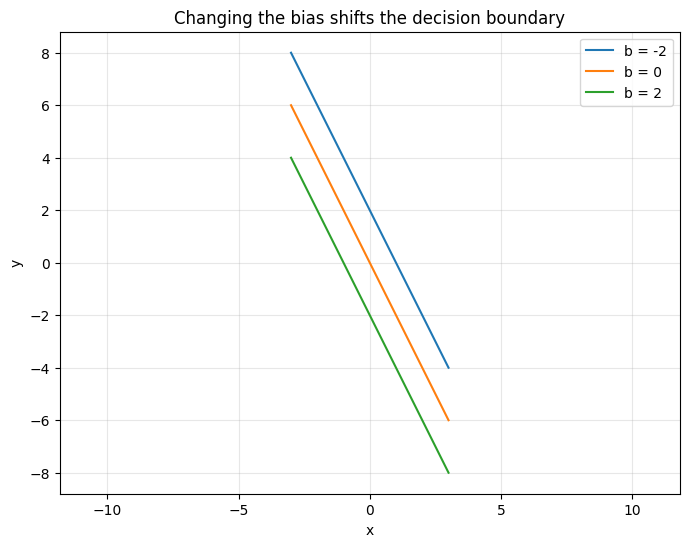

In [5]:
W = np.array([2.0, 1.0])
biases = [-2.0, 0.0, 2.0]
x = np.linspace(-3, 3, 300)

plt.figure(figsize=(8, 6))
for b in biases:
    y = -(W[0] * x + b) / W[1]
    plt.plot(x, y, label=f"b = {b:g}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Changing the bias shifts the decision boundary")
plt.grid(True, alpha=0.3)
plt.legend()
plt.axis("equal")
plt.show()


## 6. A plane in 3D

In three dimensions, the boundary is a plane. We plot \(2x+y+z-3=0\), or \(z=3-2x-y\).

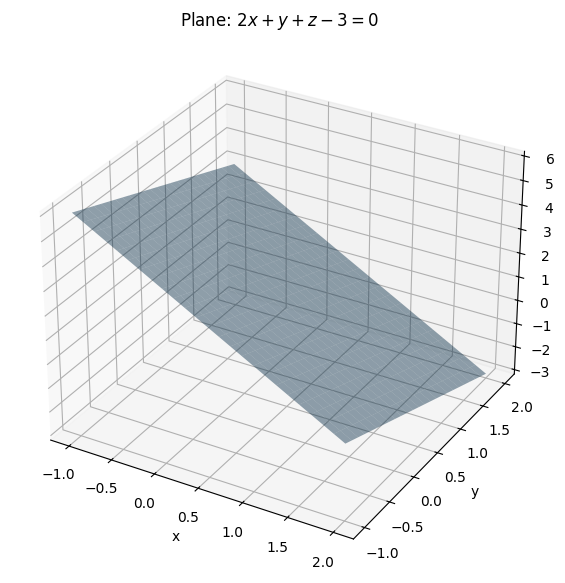

In [6]:
from mpl_toolkits.mplot3d import Axes3D  # registers 3D projection support

W3 = np.array([2.0, 1.0, 1.0])
b3 = -3.0

xx, yy = np.meshgrid(np.linspace(-1, 2, 25), np.linspace(-1, 2, 25))
zz = -(W3[0] * xx + W3[1] * yy + b3) / W3[2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(xx, yy, zz, alpha=0.45)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title(r"Plane: $2x+y+z-3=0$")
plt.show()


## 7. A point's distance from the 3D plane

We can calculate the distance using the same formula. The dimension changes, but the method does not.

In [7]:
W3 = np.array([2.0, 1.0, 1.0])
b3 = -3.0
S3 = np.array([1.0, 1.0, 1.0])

signed_distance_3d = (W3 @ S3 + b3) / np.linalg.norm(W3)
actual_distance_3d = abs(signed_distance_3d)

print("Point S:", S3)
print("Signed distance:", signed_distance_3d)
print("Actual distance:", actual_distance_3d)


Point S: [1. 1. 1.]
Signed distance: 0.4082482904638631
Actual distance: 0.4082482904638631


## 8. Connection to Classification

A linear classifier can compute the decision score:

$$
f(\mathbf{S})=\mathbf{W}^T\mathbf{S}+b
$$

The sign of the score indicates which side of the decision boundary the point lies on.

Dividing the score by the magnitude of the weight vector gives the signed geometric distance:

$$
d_{\text{signed}}=\frac{f(\mathbf{S})}{\|\mathbf{W}\|}
$$

In SVM, the geometry of the decision boundary and its margin is central. Logistic Regression uses a linear score to calculate class probabilities.

**Important distinction:** The raw score and the geometric distance are not the same quantity unless the score is normalized by $\|\mathbf{W}\|$.

## 9. Self-check

1. What does the sign of signed distance tell you?
2. Why do we divide by \(\|\mathbf{W}\|\)?
3. What is the actual geometric distance if the signed distance is \(-2.5\)?
4. What does the bias term \(b\) do to a boundary when \(\mathbf{W}\) is fixed?
5. What does a signed distance of zero mean?


### Answers

1. Which side of the oriented boundary the point lies on.
2. To normalize by the magnitude of the normal vector and obtain geometric distance.
3. \(2.5\).
4. It shifts the boundary without changing the normal direction.
5. The point lies on the boundary.
